# Corrected OLDI Seed: Amazigh PEFT adaptive search

Training corpus: **openlanguagedata/oldi_seed, zgh_Tfng**, pinned to a revision containing the 2025 expert corrections. 6,193 Standard Moroccan Amazigh sentences in Neo-Tifinagh, from **203 source articles** in the pinned release.

The blog pilot is preserved separately. This is continued monolingual causal-LM adaptation, not translation or instruction tuning. Use the `text` field only. Group source articles before splitting; sentences are not independent documents.

`mood_state = MoodState.TINY`: 1% of training and validation target tokens, 50 steps per arm. `MoodState.FULL`: all training chunks, equal adaptive-search budgets, three-seed promotion, selected models trained to MAX_STEPS. Tiny evaluates at the final step only to avoid repeated test overhead.

Validation is a source-group-disjoint OLDI split so FLORES+ devtest stays locked. Corrected FLORES+ `zgh_Tfng/devtest` is configured for final evaluation; it requires access acceptance and may share source articles with Seed. The final cell rejects overlap, rather than claiming an independent test by dataset name alone. Bootstrap by source article, not sentence. A new native-authored long-form test and fluent-speaker assessment remain desirable.

The search is a bounded autoresearch-inspired hyperparameter loop, not an autonomous code-editing agent. ProDiaL uses an independent reimplementation with explicitly modified identity-preserving initialization. Fallback Mamba timings are implementation-specific. No fluency or winner claim is presumed.

Sources: https://oldi.org/cards/flores/zgh_Tfng and https://aclanthology.org/2025.wmt-1.82/


In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'transformers==4.46.3', 'datasets==3.1.0', 'huggingface-hub<1',
    'pandas', 'matplotlib', 'mambapy==1.2.0'])
import torch, transformers, datasets
assert torch.cuda.is_available(), 'Select a GPU; Kaggle requires phone verification.'
print(torch.__version__, transformers.__version__, datasets.__version__, torch.cuda.get_device_name(0))
assert transformers.__version__=='4.46.3', ('environment drift',transformers.__version__)
assert datasets.__version__=='3.1.0', ('environment drift',datasets.__version__)
import mambapy
assert mambapy.__file__.startswith('/usr/local/lib/python3.13/dist-packages'), mambapy.__file__
from torchvision.ops import nms
print('torchvision nms import ok')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 81.6 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
pathos 0.3.5 requires dill>=0.4.1, but you have dill 0.3.8 which is incompatible.
pathos 0.3.5 requires multiprocess>=0.70.19, but you have multiprocess 0.70.16 which is incompatible.
s3fs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
litellm 1.85.7 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
tpot 1.1.0 requires dill>=0.3.9, but you have dill 0.3.8 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12

2.11.0+cu128 4.46.3 3.1.0 Tesla T4
torchvision nms import ok


## 1. Two modes and a preregistered compute budget
Edit this cell before running. A fresh output directory is selected by a protocol hash.
The maximum is a finite experimental budget, not the largest value the hardware can tolerate.
Full default: 8 proposals/arm Ã— 100 steps, top two/arm Ã— 3 seeds Ã— 300 steps,
then the selected configuration/arm Ã— 3 seeds Ã— 1,000 steps. That is at most 16,800
optimizer steps, plus validation, generation and model-loading time. Inspect measured
throughput and Kaggle quota before running full. Lower all arms' budgets together if needed.
No repeated correctness sweep: reuse GPU-tested primitives and run adapter unit tests once in tiny.

In [2]:
import os, json, math, time, random, hashlib, unicodedata, gc, traceback, platform
from pathlib import Path
from enum import Enum
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
from huggingface_hub import HfApi

class MoodState(str, Enum):
    TINY = 'tiny'
    FULL = 'full'

mood_state = MoodState.FULL
TINY_STEPS = 50           
MAX_STEPS = 1000          
SEARCH_STEPS = 100
PROMOTION_STEPS = 300
PROPOSALS_PER_ARM = 8
TOP_K = 2
SEEDS = [42, 43, 44]
MAX_LEN, BATCH, ACCUM = 256, 2, 4
RUN_SEARCH = False
ONLY_SEARCH = False
PROMOTE_ONLY = False
PROMOTE_SPECS = []
FINAL_ONLY = False
FINAL_SPECS = [{"family": "pythia", "method": "lora", "rank": 8, "lr": 0.001, "warmup_ratio": 0.1, "weight_decay": 0.0, "alpha_ratio": 2.0, "id": "pythia_lora_a52ad0d7a849"}, {"family": "mamba", "method": "lora", "rank": 8, "lr": 0.002, "warmup_ratio": 0.03, "weight_decay": 0.0, "alpha_ratio": 4.0, "id": "mamba_lora_dea7ad01262f"}, {"family": "mamba", "method": "prodial", "rank": 4, "lr": 0.002, "warmup_ratio": 0.2, "weight_decay": 0.0, "alpha_ratio": 2.0, "block_size": 8, "init_eps": 0.01, "id": "mamba_prodial_fc8b58a0f2f3"}]
EVAL_ONLY = True
TRAIN_STATS = {"pythia_lora_a52ad0d7a849/42": {"trainable_params": 1179648, "train_tokens_per_second": 2021.383266139228, "peak_train_gib": 1.456446647644043}, "pythia_lora_a52ad0d7a849/43": {"trainable_params": 1179648, "train_tokens_per_second": 2021.7390670427394, "peak_train_gib": 1.4621315002441406}, "pythia_lora_a52ad0d7a849/44": {"trainable_params": 1179648, "train_tokens_per_second": 2031.2982481454321, "peak_train_gib": 1.4595680236816406}, "mamba_lora_dea7ad01262f/42": {"trainable_params": 1179648, "train_tokens_per_second": 555.9671723708058, "peak_train_gib": 5.547576904296875}, "mamba_lora_dea7ad01262f/43": {"trainable_params": 1179648, "train_tokens_per_second": 554.9119961112347, "peak_train_gib": 5.548519611358643}, "mamba_lora_dea7ad01262f/44": {"trainable_params": 1179648, "train_tokens_per_second": 555.0618183998608, "peak_train_gib": 5.548494815826416}, "mamba_prodial_fc8b58a0f2f3/42": {"trainable_params": 1124352, "train_tokens_per_second": 517.2895160900058, "peak_train_gib": 5.867128849029541}, "mamba_prodial_fc8b58a0f2f3/43": {"trainable_params": 1124352, "train_tokens_per_second": 516.3023165178223, "peak_train_gib": 5.8757195472717285}, "mamba_prodial_fc8b58a0f2f3/44": {"trainable_params": 1124352, "train_tokens_per_second": 516.6557609071608, "peak_train_gib": 5.868156909942627}}
ADAPTER_DATASET_SLUG = 'charrajzakariaa/amazigh-oldi-final-adapters'
BAKED_HF_TOKEN = "YOUR_HF_TOKEN_HERE"
RUN_FINAL_TEST = False    
RUN_ADAPTER_TESTS = False
MAX_TRAIN_GPU_HOURS = 20.0
REQUIRE_VALIDATION_QUALITY_GATE = True
MAX_VALIDATION_CHAR_REPETITION = .6

DATASET = 'openlanguagedata/oldi_seed'
DATA_CONFIG = 'zgh_Tfng'
DATA_SPLIT, TEXT_COLUMN, URL_COLUMN = 'train', 'text', 'url'
DATA_REVISION_REQUESTED = '4bcdd99e91519487e98eef8efad17200959b8367'
INDEPENDENT_TEST_DATASET = 'openlanguagedata/flores_plus'
TEST_CONFIG = 'zgh_Tfng'
TEST_SPLIT, TEST_TEXT_COLUMN, TEST_URL_COLUMN = 'devtest', 'text', 'url'
TEST_REVISION_REQUESTED = 'e707e62e762a9e2faca3933aa315f4665cc3cd8f'
LANGUAGE_VARIETY = 'Standard Moroccan Amazigh (zgh), Neo-Tifinagh (Tfng)'
SOURCE_RIGHTS = 'OLDI Seed CC-BY-SA-4.0; cite expert corrections and original Seed paper'
HUMAN_EVALUATION_COMPLETE = False
MODELS = {'pythia':'EleutherAI/pythia-160m', 'mamba':'state-spaces/mamba-130m-hf'}
ARMS = [('pythia','lora'), ('mamba','lora'), ('mamba','prodial')]
FP16 = not torch.cuda.is_bf16_supported()
AMP_DTYPE = torch.float16 if FP16 else torch.bfloat16
assert isinstance(mood_state, MoodState)
assert TINY_STEPS in (50,70)
assert 0 < SEARCH_STEPS <= PROMOTION_STEPS <= MAX_STEPS
assert PROPOSALS_PER_ARM >= TOP_K >= 1 and len(SEEDS) >= 3

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def write_json(path, value):
    path = Path(path); tmp = path.with_suffix('.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False))
    tmp.replace(path)

def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        HF_TOKEN = None
HF_TOKEN_SOURCE = 'env' if os.environ.get('HF_TOKEN') else ('secrets-client' if HF_TOKEN else 'none')
if not HF_TOKEN and BAKED_HF_TOKEN:
    HF_TOKEN = BAKED_HF_TOKEN; HF_TOKEN_SOURCE = 'baked-fallback'
    print('Using baked-in HF token: approved single-run fallback only; revoke immediately after outputs land.')
if HF_TOKEN:
    from huggingface_hub import login
    login(token=HF_TOKEN)
    print('Hugging Face authentication configured.')
else:
    print('No HF_TOKEN secret attached; gated FLORES+ test access will fail until terms are accepted and a token is provided.')
api = HfApi(token=HF_TOKEN) if HF_TOKEN else HfApi()
MODEL_REVISIONS = {k:api.model_info(v).sha for k,v in MODELS.items()}
DATA_REVISION = api.dataset_info(DATASET,revision=DATA_REVISION_REQUESTED).sha
PROTOCOL = dict(validation_checks_search=4,validation_checks_final=10,data_config=DATA_CONFIG,test_config=TEST_CONFIG,validation='OLDI article-group-disjoint 10%',min_chars=2,eval_only=EVAL_ONLY,code_sha256='97c09e4916d042eb5a418312494122891d4d5a20978cafda5bb7ff534f0abdfb', version=3, mood_state=mood_state.value, tiny_steps=TINY_STEPS,
    max_steps=MAX_STEPS, search_steps=SEARCH_STEPS, promotion_steps=PROMOTION_STEPS,
    proposals_per_arm=PROPOSALS_PER_ARM, top_k=TOP_K, seeds=SEEDS, max_len=MAX_LEN,
    batch=BATCH, accum=ACCUM, dataset=DATASET, data_revision=DATA_REVISION,
    models=MODELS, model_revisions=MODEL_REVISIONS, independent_test=INDEPENDENT_TEST_DATASET,
    test_split=TEST_SPLIT, test_columns=[TEST_TEXT_COLUMN,TEST_URL_COLUMN],
    test_revision_requested=TEST_REVISION_REQUESTED, text_column=TEXT_COLUMN,url_column=URL_COLUMN,
    data_split=DATA_SPLIT,split_seed=2026,selection_metric='validation token-weighted NLL',
    budget_control='fixed steps and matched token order per seed; no early stopping',
    prodial='independent Eq7 reimplementation; configurable identity-preserving epsilon init',
    quality_gate=REQUIRE_VALIDATION_QUALITY_GATE,max_char_repetition=MAX_VALIDATION_CHAR_REPETITION,
    torch=torch.__version__,transformers=transformers.__version__,datasets=datasets.__version__)
PROTOCOL_ID = digest(PROTOCOL)[:16]
OUT = Path('/kaggle/working') / ('amazigh_oldi_'+PROTOCOL_ID); OUT.mkdir(parents=True,exist_ok=True)
write_json(OUT/'protocol.json',PROTOCOL)
write_json(OUT/'environment.json',dict(python=platform.python_version(),torch=torch.__version__,
    cuda=torch.version.cuda,transformers=transformers.__version__,datasets=datasets.__version__,
    gpu=torch.cuda.get_device_name(0),validation_precision='fp32',training_precision=str(AMP_DTYPE)))
(OUT/'pip_freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
print('MODE',mood_state.value,'OUTPUT',OUT,'FULL max planned steps',
      3*(PROPOSALS_PER_ARM*SEARCH_STEPS + TOP_K*len(SEEDS)*PROMOTION_STEPS + len(SEEDS)*MAX_STEPS))


Using baked-in HF token: approved single-run fallback only; revoke immediately after outputs land.
Hugging Face authentication configured.
MODE full OUTPUT /kaggle/working/amazigh_oldi_f7d3f9f966c6ab8e FULL max planned steps 16800


## Data audit: corrected sentences and source-article grouping
Retain short valid sentences; do not apply the blog pilot's 50-character cutoff. Verify all rows are `zgh/Tfng` and that revision-3.0 corrections exist. Exact duplicates are removed. Same-source URLs and near duplicates remain in one split. An inverted 5-gram index generates candidate pairs; exact Jaccard confirms near duplicates. This avoids a quadratic scan and needs no additional package. The fixed 10% validation target is allocated by whole source groups, so its actual size can differ. No FLORES+ test content is loaded during search.


In [3]:
def normalize(text):
    return ' '.join(unicodedata.normalize('NFC', str(text)).split())

def clean_documents(raw, text_column, url_column):
    assert text_column in raw.column_names, raw.column_names
    result, seen = [], set()
    for i,row in enumerate(raw):
        if row[text_column] is None: continue
        text=normalize(row[text_column]); h=hashlib.sha256(text.encode()).hexdigest()
        if len(text)<2 or h in seen: continue
        seen.add(h)
        url=str(row.get(url_column) or f'row:{i}')
        result.append(dict(text=text,url=url,hash=h))
    return result

def shingles(text):
    words=text.casefold().split()
    return {tuple(words[i:i+5]) for i in range(max(0,len(words)-4))}

def jaccard(a,b):
    return len(a&b)/len(a|b) if a and b else 0.

def grouped_split(docs):
    from collections import defaultdict
    assert len(docs)>=20, 'Not enough usable rows.'
    parent=list(range(len(docs)));sizes=[1]*len(docs);pairs=[]
    def find(i):
        while parent[i]!=i: parent[i]=parent[parent[i]];i=parent[i]
        return i
    def union(i,j):
        i,j=find(i),find(j)
        if i==j:return
        if sizes[i]<sizes[j]:i,j=j,i
        parent[j]=i;sizes[i]+=sizes[j]
    urls={};index=defaultdict(list);sig=[]
    for i,d in enumerate(docs):
        if d['url'] in urls:union(i,urls[d['url']])
        else:urls[d['url']]=i
        s=shingles(d['text']);sig.append(s)
        candidates={j for gram in s for j in index[gram]}
        for j in candidates:
            score=jaccard(s,sig[j])
            if score>=.8:
                union(i,j);pairs.append(dict(a=d['hash'],b=docs[j]['hash'],jaccard=score))
        for gram in s:index[gram].append(i)
    groups={}
    for i,d in enumerate(docs):groups.setdefault(find(i),[]).append(d)
    groups=list(groups.values());random.Random(2026).shuffle(groups)
    assert len(groups)>=10, 'Too few independent source/duplicate groups.'
    splits={'validation':[],'train':[]};target=max(3,round(.1*len(docs)))
    for group in groups:
        name='validation' if len(splits['validation'])<target else 'train'
        splits[name].extend(group)
    assert all(splits.values())
    assert not ({d['url'] for d in splits['train']}&{d['url'] for d in splits['validation']})
    return splits,pairs

raw=load_dataset(DATASET,DATA_CONFIG,revision=DATA_REVISION,split=DATA_SPLIT)
assert len(raw)==6193, 'Pinned corrected release changed or wrong configuration.'
assert all(r['iso_639_3']=='zgh' and r['iso_15924']=='Tfng' for r in raw)
assert any(r['last_updated']=='3.0' for r in raw), 'Expected 2025 corrections missing.'
from collections import Counter
write_json(OUT/'data_provenance.json',dict(dataset=DATASET,config=DATA_CONFIG,revision=DATA_REVISION,
    original_rows=len(raw),source_articles=len(set(raw['url'])),license='CC-BY-SA-4.0',
    revision_markers=dict(Counter(raw['last_updated'])),correction_paper='https://aclanthology.org/2025.wmt-1.82/'))
docs=clean_documents(raw,TEXT_COLUMN,URL_COLUMN)
SPLITS,NEAR_DUPLICATES=grouped_split(docs)
write_json(OUT/'near_duplicates.json',NEAR_DUPLICATES)
write_json(OUT/'split_manifest.json',{k:[dict(url=d['url'],hash=d['hash']) for d in v] for k,v in SPLITS.items()})
TOKENIZERS={f:AutoTokenizer.from_pretrained(m,revision=MODEL_REVISIONS[f]) for f,m in MODELS.items()}
selection_docs=SPLITS['train']+SPLITS['validation']
SAME_TOKENIZER=(TOKENIZERS['pythia'].get_vocab()==TOKENIZERS['mamba'].get_vocab() and
    all(TOKENIZERS['pythia'].encode(d['text'])==TOKENIZERS['mamba'].encode(d['text']) for d in selection_docs))
assert SAME_TOKENIZER, 'Primary cross-model token NLL requires equal tokenizers; redesign metric if unequal.'

def chunks(rows,tok):
    blocks=[]
    for d in rows:
        ids=tok.encode(d['text'],add_special_tokens=False)+[tok.eos_token_id]
        for start in range(0,len(ids)-1,MAX_LEN-1):
            block=ids[start:start+MAX_LEN]
            if len(block)>=2: blocks.append(block)
    return blocks

def token_fraction(blocks,fraction,seed=2026):
    budget=max(1,math.ceil(sum(len(b)-1 for b in blocks)*fraction))
    order=list(range(len(blocks)));random.Random(seed).shuffle(order)
    chosen=[];remaining=budget
    for i in order:
        take=min(remaining,len(blocks[i])-1)
        if take: chosen.append(blocks[i][:take+1]);remaining-=take
        if remaining==0: break
    assert remaining==0
    return chosen

TOKEN_DATA={f:{s:chunks(SPLITS[s],t) for s in ('train','validation')} for f,t in TOKENIZERS.items()}
if mood_state==MoodState.TINY:
    for data in TOKEN_DATA.values():
        for split in ('train','validation'): data[split]=token_fraction(data[split],.01)
assert TOKEN_DATA['pythia']==TOKEN_DATA['mamba']
AUDIT=[]
for name,rows in SPLITS.items():
    chars=sum(len(d['text']) for d in rows);words=sum(len(d['text'].split()) for d in rows)
    nt=sum(len(TOKENIZERS['pythia'].encode(d['text'],add_special_tokens=False)) for d in rows) if name!='quarantine' else None
    AUDIT.append(dict(split=name,documents=len(rows),chars=chars,words=words,
        tokens=nt,tokens_per_word=nt/max(1,words) if nt is not None else None,
        tifinagh_share=sum(sum('\u2d30'<=c<='\u2d7f' for c in d['text']) for d in rows)/chars))
audit_df=pd.DataFrame(AUDIT);display(audit_df);audit_df.to_csv(OUT/'data_audit.csv',index=False)
print('TRAIN FRACTION',.01 if mood_state==MoodState.TINY else 1.,'target tokens',
      {s:sum(len(b)-1 for b in TOKEN_DATA['pythia'][s]) for s in ('train','validation')})
if len(docs)<1000: print('WARNING: small-corpus pilot; more steps cannot replace representative data.')


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/46 [00:00<?, ?it/s]

zgh_Tfng.jsonl: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

,split,documents,chars,words,tokens,tokens_per_word,tifinagh_share
0,validation,652,77974,14660,185606,12.660709,0.783633
1,train,5540,683019,128132,1622681,12.664135,0.781868


TRAIN FRACTION 1.0 target tokens {'train': 1622681, 'validation': 185606}


## 3. GPU-tested adapter implementations; one optional unit check
LoRA: `W + (alpha/r)BA`. ProDiaL: `s W Db + BA`, block-diagonal `Db`.
Dense effective weights are materialized during training and merged before inference.
Both Mamba methods target exactly `in_proj`/`out_proj`. Pythia targets its attention/MLP linears.

ProDiaL is **not an exact paper reproduction**: its configurable `Da=epsilon I`,
`s=1/(1-epsilon)` preserves pretrained weights and initializes diagonal gradients.
The earlier epsilon=1e-4 produced inactive ReLU diagonal entries. The search can compare
1e-4, 0.01 and 0.05; all are modified initialization and must be disclosed. No claim that
this resolves the authors' supplement/code discrepancy. See Ham et al., CVPR 2025,
https://arxiv.org/abs/2411.15224. Matrix statistics include inactive diagonals and residual norms.

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import parametrize

class LoRAWeight(nn.Module):
    def __init__(self, weight, rank=8, alpha=16):
        super().__init__()
        out_f,in_f = weight.shape
        self.A = nn.Parameter(torch.randn(rank,in_f,device=weight.device)*.02)
        self.B = nn.Parameter(torch.zeros(out_f,rank,device=weight.device))
        self.scale = alpha/rank
    def forward(self, W):
        with torch.autocast('cuda', enabled=False):
            return (W.float() + self.scale*(self.B @ self.A)).to(W.dtype)

class ProDiaLWeight(nn.Module):
    def __init__(self, weight, block_size=8, rank=8, init_eps=1e-4):
        super().__init__()
        out_f,in_f = weight.shape
        assert in_f % block_size == 0
        self.block_size = block_size
        eye = torch.eye(block_size, device=weight.device)
        self.register_buffer('eye', eye)
        eps = float(init_eps)
        assert 0 < eps < 1
        self.Da = nn.Parameter((eps*eye).repeat(in_f//block_size,1,1))
        self.s = nn.Parameter(torch.full((out_f,),1/(1-eps),device=weight.device))
        self.A = nn.Parameter(torch.randn(rank,in_f,device=weight.device)*.02)
        self.B = nn.Parameter(torch.zeros(out_f,rank,device=weight.device))
    def blocks(self):
        return self.eye - F.relu(self.eye*self.Da) + (1-self.eye)*self.Da
    def forward(self, W):
        with torch.autocast('cuda', enabled=False):
            shaped = W.float().reshape(W.shape[0],-1,self.block_size)
            WD = torch.einsum('onk,nkj->onj',shaped,self.blocks()).reshape_as(W)
            return (self.s[:,None]*WD + self.B@self.A).to(W.dtype)

def attach(model, method, targets, rank, block_size=None, alpha_ratio=2., init_eps=1e-4):
    rank = int(rank)
    if method == 'prodial': block_size = int(block_size)
    for p in model.parameters(): p.requires_grad_(False)
    names = []
    for name, layer in list(model.named_modules()):
        if isinstance(layer,nn.Linear) and name.split('.')[-1] in targets:
            adapter = (LoRAWeight(layer.weight,rank,alpha_ratio*rank) if method=='lora'
                       else ProDiaLWeight(layer.weight,block_size,rank,init_eps))
            parametrize.register_parametrization(layer,'weight',adapter)
            names.append(name)
    assert names, 'No matching projector layers'
    return names

def merge(model):
    for layer in list(model.modules()):
        if parametrize.is_parametrized(layer, 'weight'):
            parametrize.remove_parametrizations(layer,'weight',leave_parametrized=True)
    return model

def adapter_tests():
    for method in ('lora','prodial'):
        seed_all(1)
        layer = nn.Linear(16,32).cuda()
        W = layer.weight.detach().clone()
        adapter = LoRAWeight(W,4,8) if method=='lora' else ProDiaLWeight(W,4,4)
        torch.testing.assert_close(adapter(W),W,rtol=1e-5,atol=1e-6)
        if method=='prodial':
            with torch.no_grad(): adapter.Da.add_(torch.randn_like(adapter.Da)*1e-5)
            Db = torch.block_diag(*adapter.blocks().unbind())
            torch.testing.assert_close(adapter(W), adapter.s[:,None]*(W@Db)+adapter.B@adapter.A)
        layer.requires_grad_(False)
        parametrize.register_parametrization(layer,'weight',adapter)
        opt = torch.optim.AdamW(adapter.parameters(),lr=1e-3,weight_decay=0)
        x,y = torch.randn(4,16,device='cuda'), torch.randn(4,32,device='cuda')
        for _ in range(2):
            opt.zero_grad(); F.mse_loss(layer(x),y).backward(); opt.step()
        assert adapter.A.grad is not None and adapter.A.grad.abs().sum()>0
        assert adapter.B.grad is not None and adapter.B.grad.abs().sum()>0
        if method=='prodial':
            assert adapter.Da.grad.diagonal(dim1=-2,dim2=-1).abs().sum()>0
            assert adapter.s.grad.abs().sum()>0
        torch.testing.assert_close(layer.parametrizations.weight.original,W)
        before = layer(x).detach(); merge(layer)
        torch.testing.assert_close(layer(x),before)
        print(method,'identity, gradients, frozen base, merged output: PASS')
if RUN_ADAPTER_TESTS: adapter_tests()


## 4. Training engine: fixed budgets, cosine schedule, validation checkpoints
Reuses the executed pilot's model loading, batching, token-weighted metrics and backend.
FP32 validation; mixed-precision training with scaler, clipping and explicit finite checks.
Training retains every chunk, including short tails: full uses 100% of the training split.
Target counts vary across updates but match across arms within each seed and stage because
the chunks, batching and sampling order are identical. Validation/test are never training data.
No early stopping: every successful trial runs its complete maximum budget, retaining the
best validation checkpoint. Record skipped updates (none allowed), training loss, validation
curves, wall time, throughput, peak training memory and matrix state. Failed trials are logged.
Trial resume is at completed-trial granularity, not midway through an interrupted optimizer.

In [5]:
def batch_tensors(blocks, tok):
    length = max(map(len,blocks))
    pad = tok.eos_token_id
    ids = torch.full((len(blocks),length),pad,dtype=torch.long,device='cuda')
    mask = torch.zeros_like(ids)
    labels = torch.full_like(ids,-100)
    for i,block in enumerate(blocks):
        n = len(block); ids[i,:n] = torch.tensor(block,device='cuda'); mask[i,:n] = 1; labels[i,:n] = ids[i,:n]
    return dict(input_ids=ids, attention_mask=mask), labels

def token_loss(model, blocks, tok, accuracy=False):
    inputs,labels = batch_tensors(blocks,tok)
    logits = model(**inputs,use_cache=False).logits[:,:-1].float()
    target = labels[:,1:]
    loss_sum = F.cross_entropy(logits.reshape(-1,logits.size(-1)),target.reshape(-1),
                              ignore_index=-100,reduction='sum')
    valid = target!=-100
    n = valid.sum()
    correct = ((logits.argmax(-1)==target)&valid).sum() if accuracy else 0
    return loss_sum,n,correct

@torch.no_grad()
def evaluate(model, blocks, tok):
    model.eval()
    if getattr(model.config, 'model_type', None) == 'mamba':
        import transformers.models.mamba.modeling_mamba as mm
        for layer in model.modules():
            if isinstance(layer, mm.MambaMixer) and layer.use_mambapy:
                assert not any(isinstance(x, nn.Dropout) for x in layer.modules())
                layer.training = True
    total_loss = 0.; n = correct = 0
    for start in range(0,len(blocks),BATCH):
        with torch.autocast('cuda',enabled=False):
            l,t,c = token_loss(model,blocks[start:start+BATCH],tok,True)
        total_loss+=l.item(); n+=t.item(); correct+=c.item()
    assert n>0
    loss=total_loss/n
    return dict(loss=loss,ppl=math.exp(loss) if loss<700 else None,accuracy=correct/n,tokens=n)

def load_model(family):
    model = AutoModelForCausalLM.from_pretrained(MODELS[family], revision=MODEL_REVISIONS[family],
                                                torch_dtype=torch.float32).cuda()
    if family=='mamba':
        import transformers.models.mamba.modeling_mamba as mm
        if not mm.is_fast_path_available:
            from mambapy.pscan import pscan
            mm.pscan = pscan
            model.config.use_mambapy = True
            for layer in model.modules():
                if isinstance(layer,mm.MambaMixer): layer.use_mambapy = True
        model._benchmark_backend = 'mamba_cuda_kernels' if mm.is_fast_path_available else 'mamba_parallel_scan_train_and_eval_cached_sequential_decode'
    else:
        model._benchmark_backend = 'pythia_'+str(getattr(model.config,'_attn_implementation','unknown'))
    return model

def adapter_state(model):
    return {n:p.detach().cpu().clone() for n,p in model.named_parameters() if p.requires_grad}

def load_adapter_state(model, state):
    expected={n for n,p in model.named_parameters() if p.requires_grad}
    assert expected==set(state), 'Adapter checkpoint keys differ'
    with torch.no_grad():
        for n,p in model.named_parameters():
            if n in state: p.copy_(state[n].to(p.device))


In [6]:
def generation_diagnostics(text):
    chars=list(text);grams=[tuple(chars[i:i+4]) for i in range(max(0,len(chars)-3))]
    words=text.split();bigrams=list(zip(words,words[1:]))
    return dict(char_4gram_repetition=1-len(set(grams))/len(grams) if grams else None,
        distinct_1=len(set(words))/len(words) if words else None,
        distinct_2=len(set(bigrams))/len(bigrams) if bigrams else None,
        replacement_character_count=text.count('ï¿½'))

@torch.no_grad()
def generation_probes(model,tok,rows,run_id,seed):
    model.eval();result=[]
    for d in rows[:min(20,len(rows))]:
        tokens=tok.encode(d['text'],add_special_tokens=False)
        if len(tokens)<40: continue
        prefix=min(64,len(tokens)//3);x=torch.tensor([tokens[:prefix]],device='cuda')
        with torch.autocast('cuda',dtype=AMP_DTYPE):
            y=model.generate(input_ids=x,attention_mask=torch.ones_like(x),max_new_tokens=64,
                do_sample=False,use_cache=True,pad_token_id=tok.eos_token_id)
        continuation=tok.decode(y[0,prefix:],skip_special_tokens=True)
        reference=tok.decode(tokens[prefix:prefix+64],skip_special_tokens=True)
        result.append(dict(run_id=run_id,seed=seed,document=d['hash'],prompt=tok.decode(tokens[:prefix]),
            continuation=continuation,reference=reference,**generation_diagnostics(continuation)))
    return result

TRAIN_BLOCKS={f:data['train'] for f,data in TOKEN_DATA.items()}
assert all(TRAIN_BLOCKS.values()), 'The selected training split is empty.'
BASE_VALIDATION={}

def targets_for(family):
    return ('query_key_value','dense','dense_h_to_4h','dense_4h_to_h') if family=='pythia' else ('in_proj','out_proj')

def attach_spec(model,spec):
    return attach(model,spec['method'],targets_for(spec['family']),spec['rank'],spec.get('block_size'),
                  spec.get('alpha_ratio',2.),spec.get('init_eps',1e-4))

def matrix_diagnostics(model):
    stats=[]
    for name,layer in model.named_modules():
        if parametrize.is_parametrized(layer,'weight'):
            a=layer.parametrizations.weight[0]
            row=dict(layer=name,residual_norm=float((a.B.detach()@a.A.detach()).norm()))
            if isinstance(a,ProDiaLWeight):
                blocks=a.blocks().detach();diag=blocks.diagonal(dim1=-2,dim2=-1)
                row.update(block_width=a.block_size,block_count=blocks.shape[0],diag_mean=float(diag.mean()),
                    diag_min=float(diag.min()),diag_max=float(diag.max()),
                    offdiagonal_norm=float((blocks-torch.diag_embed(diag)).norm()),
                    inactive_aux_diag_fraction=float((a.Da.detach().diagonal(dim1=-2,dim2=-1)<=0).float().mean()),
                    scale_mean=float(a.s.detach().mean()))
            stats.append(row)
    return stats

def used_hours():
    return sum(json.loads(p.read_text()).get('wall_seconds',0.) for p in OUT.glob('trial_*.json'))/3600

def run_trial(spec,seed,steps,stage):
    identity=dict(protocol=PROTOCOL_ID,spec=spec,seed=seed,steps=steps,stage=stage)
    key='trial_'+digest(identity)[:20]; path=OUT/(key+'.json');ckpt=OUT/(key+'.pt')
    if path.exists():
        cached=json.loads(path.read_text())
        if cached['status']=='ok' and ckpt.exists(): return cached
        if cached['status']=='failed': return cached
    if used_hours()>=MAX_TRAIN_GPU_HOURS: raise RuntimeError('Compute cap reached: resume or revise all arms budgets.')
    started=time.perf_counter();model=opt=scaler=None
    try:
        seed_all(seed);gc.collect();torch.cuda.empty_cache()
        model=load_model(spec['family']);tok=TOKENIZERS[spec['family']]
        base_params=sum(p.numel() for p in model.parameters());attach_spec(model,spec)
        trainables=[p for p in model.parameters() if p.requires_grad]
        count=sum(p.numel() for p in trainables)
        assert .9e6 <= count <= 1.3e6, 'Outside preregistered adapter budget band'
        if spec['family'] not in BASE_VALIDATION: BASE_VALIDATION[spec['family']]=evaluate(model,TOKEN_DATA[spec['family']]['validation'],tok)
        opt=torch.optim.AdamW(trainables,lr=spec['lr'],weight_decay=spec['weight_decay'])
        scaler=torch.amp.GradScaler('cuda',enabled=FP16)
        blocks=TRAIN_BLOCKS[spec['family']];rng=random.Random(seed)
        order=list(range(len(blocks)));rng.shuffle(order);cursor=0
        history=[];best_loss=float('inf');best_step=0;trained_tokens=0;training_s=0.;best_state=None
        interval=steps if mood_state==MoodState.TINY else max(1,steps//(4 if stage in ('search','promotion') else 10));warmup=max(1,round(steps*spec['warmup_ratio']))
        torch.cuda.reset_peak_memory_stats();peak=0.
        for step in range(1,steps+1):
            if used_hours()+(time.perf_counter()-started)/3600>=MAX_TRAIN_GPU_HOURS:
                raise RuntimeError('Compute cap reached within trial')
            model.train();torch.cuda.synchronize();t0=time.perf_counter();micro=[]
            for _ in range(ACCUM):
                rows=[]
                for _ in range(BATCH):
                    if cursor==len(order): rng.shuffle(order);cursor=0
                    rows.append(blocks[order[cursor]]);cursor+=1
                micro.append(rows)
            target_tokens=sum(len(b)-1 for rows in micro for b in rows)
            factor=step/warmup if step<=warmup else .1+.9*.5*(1+math.cos(math.pi*(step-warmup)/max(1,steps-warmup)))
            for group in opt.param_groups: group['lr']=spec['lr']*factor
            opt.zero_grad(set_to_none=True);train_sum=0.
            for rows in micro:
                with torch.autocast('cuda',dtype=AMP_DTYPE): loss_sum,_,_=token_loss(model,rows,tok)
                assert torch.isfinite(loss_sum), 'Nonfinite training loss'
                train_sum+=float(loss_sum.detach());scaler.scale(loss_sum/target_tokens).backward()
            scaler.unscale_(opt)
            assert all(p.grad is None or torch.isfinite(p.grad).all() for p in trainables), 'Nonfinite gradient: no skipped updates allowed'
            torch.nn.utils.clip_grad_norm_(trainables,1.);scaler.step(opt);scaler.update()
            torch.cuda.synchronize();training_s+=time.perf_counter()-t0;trained_tokens+=target_tokens
            peak=max(peak,torch.cuda.max_memory_allocated()/2**30)
            row=dict(step=step,train_loss=train_sum/target_tokens,lr=spec['lr']*factor,train_tokens=trained_tokens)
            if step%interval==0 or step==steps:
                metrics=evaluate(model,TOKEN_DATA[spec['family']]['validation'],tok)
                assert math.isfinite(metrics['loss'])
                row.update(val_loss=metrics['loss'],val_ppl=metrics['ppl'],val_accuracy=metrics['accuracy'])
                if metrics['loss']<best_loss:
                    best_loss=metrics['loss'];best_step=step;best_state=adapter_state(model)
                torch.cuda.reset_peak_memory_stats()
                print(stage,spec['id'],seed,step,'val_ppl',round(metrics['ppl'],4))
            history.append(row)
        load_adapter_state(model,best_state);torch.save(best_state,ckpt)
        quality=None
        if stage in ('promotion','final_training'):
            probes=generation_probes(model,tok,SPLITS['validation'][:3],spec['id'],seed)
            repetition=[p['char_4gram_repetition'] for p in probes if p['char_4gram_repetition'] is not None]
            quality=dict(probes=probes,mean_char_repetition=float(np.mean(repetition)) if repetition else None,
                passed=bool(repetition) and float(np.mean(repetition))<=MAX_VALIDATION_CHAR_REPETITION)
        result=dict(**identity,status='ok',checkpoint=str(ckpt),id=spec['id'],family=spec['family'],method=spec['method'],
            best_val_loss=best_loss,best_val_ppl=math.exp(best_loss),best_step=best_step,
            trainable_params=count,base_params=base_params,train_tokens=trained_tokens,
            train_seconds=training_s,train_tokens_per_second=trained_tokens/training_s,peak_train_gib=peak,
            backend=model._benchmark_backend,baseline_val=BASE_VALIDATION[spec['family']],
            history=history,matrix_stats=matrix_diagnostics(model),validation_generation=quality,
            wall_seconds=time.perf_counter()-started)
    except Exception as exc:
        result=dict(**identity,id=spec['id'],family=spec['family'],method=spec['method'],status='failed',
                    error=str(exc),traceback=traceback.format_exc(),wall_seconds=time.perf_counter()-started)
        print('FAILED',spec['id'],str(exc))
    finally:
        model=opt=scaler=None
        gc.collect();torch.cuda.empty_cache()
    write_json(path,result)
    return result


## 5. Adaptive autoresearch-style configuration search
The protected protocol (data, metrics, test lock, token budgets, targets) cannot be mutated.
Only LR, warmup, weight decay, LoRA scale, and ProDiaL block/residual allocation/init vary.
LoRA rank 8 gives 1.18M parameters; ProDiaL (width,rank)=(4,6),(8,4),(16,1)
gives approximately 1.12â€“1.20M: a budget band, **not exactly equal parameter counts**.
Block width/rank co-vary: do not call this an isolated block-width ablation.

First proposals include prior-informed baselines, then random exploration alternates with
one-factor mutations of the current incumbent. Retain/discard based only on validation NLL.
Identical search counts and seeds across arms; failures consume a proposal and remain visible.
Promotion re-runs top candidates from scratch at the larger budget for all three seeds.
Lock by mean promotion validation loss, then train each winner at MAX_STEPS for those seeds.
No claim of global optimum. Tiny runs one configuration per arm and never freezes paper results.

In [7]:
SPACE=dict(lr=[1e-4,3e-4,1e-3,2e-3],warmup_ratio=[.03,.1,.2],weight_decay=[0.,.01],
           alpha_ratio=[1.,2.,4.],allocation=[(4,6),(8,4),(16,1)],init_eps=[1e-4,.01,.05])
write_json(OUT/'search_space.json',SPACE)

def proposal(family,method,index,incumbent,seen):
    rng=random.Random(9000+index+100*ARMS.index((family,method)))
    base=dict(family=family,method=method,rank=8,lr=1e-3,warmup_ratio=.1,weight_decay=0.,alpha_ratio=2.)
    if method=='prodial': base.update(block_size=16,rank=1,init_eps=1e-4)
    for attempt in range(200):
        s=base.copy()
        keys=['lr','warmup_ratio','weight_decay']+(['alpha_ratio'] if method=='lora' else ['allocation','init_eps'])
        if index==0 and attempt==0: pass
        elif index%2==1 and incumbent:
            s={k:v for k,v in incumbent['spec'].items() if k!='id'}
            key=rng.choice(keys);value=rng.choice(SPACE[key])
            if key=='allocation': s['block_size'],s['rank']=value
            else: s[key]=value
        else:
            for key in keys:
                value=rng.choice(SPACE[key])
                if key=='allocation': s['block_size'],s['rank']=value
                else: s[key]=value
        identity=digest(s)[:12]
        if identity not in seen:
            s['id']=f'{family}_{method}_{identity}'
            return s,identity
    raise RuntimeError('Search space exhausted')

SEARCH_RESULTS=[];CONFIRMED_RESULTS=[];PROMOTION_RESULTS=[]
if RUN_SEARCH:
    incumbents={a:None for a in ARMS};seen={a:set() for a in ARMS}
    count=1 if mood_state==MoodState.TINY else PROPOSALS_PER_ARM
    search_steps=TINY_STEPS if mood_state==MoodState.TINY else SEARCH_STEPS
    for index in ([] if (PROMOTE_ONLY or FINAL_ONLY) else range(count)):
        for arm in ARMS:
            spec,identity=proposal(*arm,index,incumbents[arm],seen[arm]);seen[arm].add(identity)
            run=run_trial(spec,42,search_steps,'tiny' if mood_state==MoodState.TINY else 'search')
            previous=incumbents[arm]
            kept=run['status']=='ok' and (previous is None or run['best_val_loss']<previous['best_val_loss'])
            if kept: incumbents[arm]=run
            SEARCH_RESULTS.append(run)
            write_json(OUT/'search_results.json',SEARCH_RESULTS)
            with (OUT/'autoresearch_log.jsonl').open('a') as log:
                log.write(json.dumps(dict(proposal=index,arm=arm,trial_id=spec['id'],decision='keep' if kept else 'discard',
                    status=run['status'],validation_loss=run.get('best_val_loss'),protocol=PROTOCOL_ID))+'\n')
    if mood_state==MoodState.FULL and not ONLY_SEARCH:
        if FINAL_ONLY:
            assert len(FINAL_SPECS)==len(ARMS), 'FINAL_ONLY requires locked specs embedded'
            LOCKED_SPECS=list(FINAL_SPECS)
            write_json(OUT/'locked_selection.json',dict(protocol=PROTOCOL_ID,specs=LOCKED_SPECS,seeds=SEEDS,max_steps=MAX_STEPS,criterion='embedded promotion lock',created_unix=time.time()))
        elif PROMOTE_ONLY:
            assert len(PROMOTE_SPECS)==TOP_K*len(ARMS), 'PROMOTE_ONLY requires top-2 specs per arm embedded'
            promoted=[dict(id=s['id'],family=s['family'],method=s['method'],spec=s) for s in PROMOTE_SPECS]
        else:
            promoted=[]
            for family,method in ([] if FINAL_ONLY else ARMS):
                successes=[r for r in SEARCH_RESULTS if r['family']==family and r['method']==method and r['status']=='ok']
                assert len(successes)>=TOP_K, 'An arm failed: repair environment, do not silently omit it.'
                promoted.extend(sorted(successes,key=lambda r:r['best_val_loss'])[:TOP_K])
        PROMOTION_RESULTS=[]
        for candidate in ([] if FINAL_ONLY else promoted):
            for seed in SEEDS:
                PROMOTION_RESULTS.append(run_trial(candidate['spec'],seed,PROMOTION_STEPS,'promotion'))
                write_json(OUT/'promotion_results.json',PROMOTION_RESULTS)
        LOCKED_SPECS=[] if not FINAL_ONLY else LOCKED_SPECS
        for family,method in ([] if FINAL_ONLY else ARMS):
            eligible=[]
            for candidate in [r for r in promoted if r['family']==family and r['method']==method]:
                reps=[r for r in PROMOTION_RESULTS if r['id']==candidate['id']]
                if len(reps)==len(SEEDS) and all(r['status']=='ok' for r in reps):
                    passes=all(r['validation_generation']['passed'] for r in reps)
                    if passes or not REQUIRE_VALIDATION_QUALITY_GATE:
                        eligible.append((np.mean([r['best_val_loss'] for r in reps]),candidate['spec']))
            assert eligible, 'No confirmed candidate passes validation generation screen. Improve training/data; do not unlock test.'
            LOCKED_SPECS.append(min(eligible,key=lambda x:x[0])[1])
        lock=dict(protocol=PROTOCOL_ID,specs=LOCKED_SPECS,seeds=SEEDS,max_steps=MAX_STEPS,
                  criterion='mean promotion validation NLL',created_unix=time.time())
        lock_path=OUT/'locked_selection.json'
        if lock_path.exists():
            old=json.loads(lock_path.read_text());assert old['specs']==LOCKED_SPECS, 'Never overwrite a differing lock.'
        else: write_json(lock_path,lock)
        for spec in ([] if PROMOTE_ONLY else LOCKED_SPECS):
            for seed in SEEDS:
                CONFIRMED_RESULTS.append(run_trial(spec,seed,MAX_STEPS,'final_training'))
                write_json(OUT/'confirmed_results.json',CONFIRMED_RESULTS)
        assert PROMOTE_ONLY or all(r['status']=='ok' for r in CONFIRMED_RESULTS)
    else: print('Tiny complete: no scientific selection, no final test, no paper result claims.')
display(pd.DataFrame([{k:r.get(k) for k in ('id','status','best_val_ppl','trainable_params','train_tokens_per_second','wall_seconds')} for r in SEARCH_RESULTS]))


""


## 6. Search, learning curves and matrix visualizations
Export CSV/JSON plus PDF (vector) and PNG figures. Show failures and non-improvements,
not only the best trial. Validation search scores are not held-out result scores.
Convergence and overfitting must be inspected; a configured maximum is not proof of convergence.

In [8]:
def save_figure(name):
    plt.tight_layout();plt.savefig(OUT/(name+'.pdf'),bbox_inches='tight')
    plt.savefig(OUT/(name+'.png'),dpi=180,bbox_inches='tight');plt.show();plt.close()

successes=[r for r in SEARCH_RESULTS if r['status']=='ok']
if successes:
    pd.DataFrame([{k:r[k] for k in ('id','family','method','best_val_ppl','trainable_params','train_tokens','train_tokens_per_second','peak_train_gib','backend')} for r in successes]).to_csv(OUT/'search_summary.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for arm in ARMS:
        runs=[r for r in successes if (r['family'],r['method'])==arm]
        label='â€“'.join(arm)
        if runs:
            axes[0].plot(range(1,len(runs)+1),np.minimum.accumulate([r['best_val_loss'] for r in runs]),marker='o',label=label)
            axes[1].scatter([r['trainable_params']/1e6 for r in runs],[r['best_val_ppl'] for r in runs],label=label)
    axes[0].set(xlabel='Successful proposal',ylabel='Incumbent validation NLL')
    axes[1].set(xlabel='Trainable parameters (millions)',ylabel='Validation PPL')
    for ax in axes: ax.legend(fontsize=8)
    save_figure('adaptive_search')
for run in CONFIRMED_RESULTS+PROMOTION_RESULTS if (CONFIRMED_RESULTS or PROMOTION_RESULTS) else successes:
    h=pd.DataFrame(run['history']);h.to_csv(OUT/(run['id']+f"_seed{run['seed']}_curves.csv"),index=False)
    plt.figure(figsize=(6,3));plt.plot(h.step,h.train_loss,label='Train minibatch NLL')
    v=h.dropna(subset=['val_loss']);plt.plot(v.step,v.val_loss,label='Validation NLL');plt.legend()
    plt.title(run['id']+f" seed {run['seed']}");plt.xlabel('Optimizer step');plt.ylabel('NLL')
    save_figure(run['id']+f"_seed{run['seed']}_curves")
    if run['method']=='prodial':
        pd.DataFrame(run['matrix_stats']).to_csv(OUT/(run['id']+f"_seed{run['seed']}_matrices.csv"),index=False)
        if run['seed']==42:
            m=load_model(run['family']);attach_spec(m,run['spec'])
            load_adapter_state(m,torch.load(run['checkpoint'],map_location='cpu',weights_only=True))
            a=next(layer.parametrizations.weight[0] for layer in m.modules() if parametrize.is_parametrized(layer,'weight'))
            plt.figure(figsize=(4,3));plt.imshow((a.blocks()[0]-a.eye).detach().cpu(),cmap='coolwarm');plt.colorbar()
            plt.title('First projector block: Db âˆ’ I');save_figure(run['id']+'_block_delta')
            del m,a;gc.collect();torch.cuda.empty_cache()


## 7. Locked independent test, baselines, generation and merged inference
Set `RUN_FINAL_TEST=True` only for full mode with a new untouched test corpus.
Near-duplicate/source overlap with **any development document** rejects the test corpus.
Read the lock before loading test; retain test hash/revision for replay. Once accessed, no
hyperparameter changes are permissible for this protocol. Baselines and all trained seeds
use identical documents. Generation prompts come from held-out document prefixes, with
reference suffixes, not from hand-picked favorable outputs. Repetition/distinct-n are
diagnostic, **not validated fluency scores**; semantic quality needs blinded human ratings.

Inference: merge adapters, use synchronized warmup and three timed repetitions, fixed
16-token cached greedy decode at contexts 128/256/512. Includes prefill, so not pure decode
latency. Mamba fallback timings are implementation-specific, never architecture speed claims.

In [9]:
@torch.no_grad()
def bench(model,tok):
    model.eval();times=[]
    for length in (128,256,512):
        ids=(tok.encode('Tamazight d tutlayt. ',add_special_tokens=False)*300)[:length]
        x=torch.tensor([ids],device='cuda');measurements=[]
        torch.cuda.reset_peak_memory_stats()
        for rep in range(5):
            torch.cuda.synchronize();start=time.perf_counter()
            with torch.autocast('cuda',dtype=AMP_DTYPE):
                output=model.generate(input_ids=x,attention_mask=torch.ones_like(x),max_new_tokens=16,
                    min_new_tokens=16,do_sample=False,use_cache=True,pad_token_id=tok.eos_token_id)
            torch.cuda.synchronize();elapsed=time.perf_counter()-start
            if rep>=2: measurements.append(elapsed)
        count=output.shape[1]-x.shape[1]
        times.append(dict(context=length,new_tokens=count,median_seconds=float(np.median(measurements)),
            ms_per_generated_token_including_prefill=1000*float(np.median(measurements))/count,
            peak_inference_gib=torch.cuda.max_memory_allocated()/2**30))
    return times

FINAL=[];BASE_TEST=[];GENERATIONS=[]
if RUN_FINAL_TEST:
    assert mood_state==MoodState.FULL, 'Tiny is never a scientific test.'
    lock=json.loads((OUT/'locked_selection.json').read_text());assert lock['protocol']==PROTOCOL_ID
    confirmed=json.loads((OUT/'confirmed_results.json').read_text())
    assert len(confirmed)==3*len(SEEDS) and all(r['status']=='ok' for r in confirmed)
    assert not REQUIRE_VALIDATION_QUALITY_GATE or all(r['validation_generation']['passed'] for r in confirmed), 'Generation collapse: test remains locked.'
    assert {r['id'] for r in confirmed}=={s['id'] for s in lock['specs']}
    assert INDEPENDENT_TEST_DATASET and INDEPENDENT_TEST_DATASET!=DATASET, 'New independent test corpus required.'
    test_revision=api.dataset_info(INDEPENDENT_TEST_DATASET,revision=TEST_REVISION_REQUESTED,token=HF_TOKEN).sha
    TEST_DOCS=clean_documents(load_dataset(INDEPENDENT_TEST_DATASET,TEST_CONFIG,revision=test_revision,split=TEST_SPLIT,token=HF_TOKEN),TEST_TEXT_COLUMN,TEST_URL_COLUMN)
    assert len(TEST_DOCS)>=20, 'At least 20 independent test documents; larger is preferable.'
    development_hashes={d['hash'] for d in docs};development_urls={d['url'] for d in docs if not d['url'].startswith('row:')}
    dev_sig=[shingles(d['text']) for d in docs]
    assert len(TEST_DOCS)*len(docs)<=25_000_000, 'Use scalable independent-test contamination audit.'
    for d in TEST_DOCS:
        assert d['hash'] not in development_hashes and d['url'] not in development_urls, 'Exact test contamination'
        sig=shingles(d['text']);assert not any(jaccard(sig,s)>=.8 for s in dev_sig), 'Near-duplicate test contamination'
    test_manifest=dict(dataset=INDEPENDENT_TEST_DATASET,config=TEST_CONFIG,revision=test_revision,
        documents=[dict(hash=d['hash'],url=d['url']) for d in TEST_DOCS],protocol=PROTOCOL_ID)
    accessed=OUT/'test_access_manifest.json'
    if accessed.exists(): assert json.loads(accessed.read_text())==test_manifest, 'Test source changed after access.'
    else: write_json(accessed,test_manifest)
    TEST_BLOCKS={f:chunks(TEST_DOCS,t) for f,t in TOKENIZERS.items()}
    assert TEST_BLOCKS['pythia']==TEST_BLOCKS['mamba'], 'Test tokenization differs; token PPL no longer comparable.'
    for family in MODELS:
        m=load_model(family);t=TOKENIZERS[family]
        per_doc=[dict(document=d['hash'],source=d['url'],**evaluate(m,chunks([d],t),t)) for d in TEST_DOCS]
        BASE_TEST.append(dict(family=family,test=evaluate(m,TEST_BLOCKS[family],t),per_document=per_doc))
        GENERATIONS.extend(generation_probes(m,t,TEST_DOCS,family+'_base',None))
        del m;gc.collect();torch.cuda.empty_cache()
    write_json(OUT/'base_test.json',BASE_TEST)
    for run in confirmed:
        m=load_model(run['family']);t=TOKENIZERS[run['family']];attach_spec(m,run['spec'])
        load_adapter_state(m,torch.load(run['checkpoint'],map_location='cpu',weights_only=True))
        test=evaluate(m,TEST_BLOCKS[run['family']],t)
        per_doc=[dict(document=d['hash'],source=d['url'],**evaluate(m,chunks([d],t),t)) for d in TEST_DOCS]
        inputs,_=batch_tensors(TEST_BLOCKS[run['family']][:1],t)
        with torch.no_grad(): before=m(**inputs,use_cache=False).logits
        merge(m)
        with torch.no_grad(): after=m(**inputs,use_cache=False).logits
        torch.testing.assert_close(before,after,rtol=1e-4,atol=1e-4)
        del before,after
        inference=bench(m,t);GENERATIONS.extend(generation_probes(m,t,TEST_DOCS,run['id'],run['seed']))
        FINAL.append(dict(id=run['id'],family=run['family'],method=run['method'],seed=run['seed'],test=test,
            per_document=per_doc,inference=inference,trainable_params=run['trainable_params'],
            train_tokens=run['train_tokens'],train_tokens_per_second=run['train_tokens_per_second'],
            peak_train_gib=run['peak_train_gib'],backend=run['backend']))
        write_json(OUT/'final_results.json',FINAL);write_json(OUT/'generation_probes.json',GENERATIONS)
        del m;gc.collect();torch.cuda.empty_cache()
else: print('Independent test locked. Validation plots available; no test or paper scores invented.')


Independent test locked. Validation plots available; no test or paper scores invented.


## 8. Uncertainty, paired comparisons and blinded human review
Report mean/sample SD across training seeds separately from document-bootstrap uncertainty.
Pair documents between methods and resample whole documents (not correlated chunks).
The bootstrap below fixes the trained seeds and estimates document-sampling uncertainty;
it is not uncertainty over all possible training seeds. Three pairwise comparisons are
exploratory; no significance declaration or p-value fishing. Human forms use opaque system
IDs; hide the key from raters. Rate fluency, coherence, lexical adequacy and script consistency
(1â€“5), with native/fluent raters and an agreed protocol. Empty ratings are not evidence.

In [10]:
def document_bootstrap(a,b,draws=2000):
    assert a.shape==b.shape and np.array_equal(a[:,1],b[:,1])
    rng=np.random.default_rng(2026);delta=[]
    for _ in range(draws):
        ix=rng.integers(0,len(a),len(a));delta.append((a[ix,0].sum()-b[ix,0].sum())/a[ix,1].sum())
    observed=(a[:,0].sum()-b[:,0].sum())/a[:,1].sum()
    return dict(delta_nll=float(observed),ci_low=float(np.quantile(delta,.025)),ci_high=float(np.quantile(delta,.975)),
                resamples=draws,unit='source_article',conditioned_on_trained_seeds=True)

SUMMARY=None
if FINAL:
    flat=pd.DataFrame([dict(id=r['id'],seed=r['seed'],test_ppl=r['test']['ppl'],test_nll=r['test']['loss'],
        accuracy=r['test']['accuracy'],trainable_params=r['trainable_params'],train_tokens_per_second=r['train_tokens_per_second'],
        peak_train_gib=r['peak_train_gib']) for r in FINAL])
    flat.to_csv(OUT/'per_seed_results.csv',index=False)
    SUMMARY=flat.groupby('id').agg(ppl_mean=('test_ppl','mean'),ppl_sd=('test_ppl','std'),
        nll_mean=('test_nll','mean'),accuracy_mean=('accuracy','mean'),accuracy_sd=('accuracy','std'),
        parameters=('trainable_params','first'),train_tokens_per_second=('train_tokens_per_second','mean'),
        peak_train_gib=('peak_train_gib','mean'))
    SUMMARY.to_csv(OUT/'comparison.csv');display(SUMMARY)
    arrays={};article_order=sorted({d['url'] for d in TEST_DOCS})
    for run_id in SUMMARY.index:
        reps=[r for r in FINAL if r['id']==run_id];values=[]
        for article in article_order:
            sums=[];tokens=[]
            for r in reps:
                scores=[d for d in r['per_document'] if d['source']==article]
                sums.append(sum(s['loss']*s['tokens'] for s in scores))
                tokens.append(sum(s['tokens'] for s in scores))
            assert len(set(tokens))==1 and tokens[0]>0
            values.append([np.mean(sums),tokens[0]])
        arrays[run_id]=np.array(values)
    assert len(article_order)>=20, 'Too few independent articles for document bootstrap.'
    from itertools import combinations
    comparisons=[dict(a=a,b=b,**document_bootstrap(arrays[a],arrays[b])) for a,b in combinations(arrays,2)]
    write_json(OUT/'paired_document_bootstrap.json',comparisons);display(pd.DataFrame(comparisons))
    plt.figure(figsize=(8,4));plt.bar(SUMMARY.index,SUMMARY.ppl_mean,yerr=SUMMARY.ppl_sd,capsize=5)
    plt.xticks(rotation=20,ha='right');plt.ylabel('Independent test PPL (mean Â± seed SD)');save_figure('test_ppl')
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].bar(SUMMARY.index,SUMMARY.train_tokens_per_second);axes[0].set_ylabel('Measured training target tokens/s')
    axes[1].bar(SUMMARY.index,SUMMARY.peak_train_gib);axes[1].set_ylabel('Peak training GiB')
    for ax in axes: ax.tick_params(axis='x',rotation=20)
    save_figure('implementation_efficiency')
    gen=pd.DataFrame(GENERATIONS);gen.to_csv(OUT/'generation_diagnostics.csv',index=False)
    systems=sorted({(r['run_id'],str(r['seed'])) for r in GENERATIONS});random.Random(2026).shuffle(systems)
    mapping={s:f'S{i:02d}' for i,s in enumerate(systems)}
    write_json(OUT/'human_blinding_key_PRIVATE.json',[dict(system=mapping[s],run_id=s[0],seed=s[1]) for s in systems])
    ratings=[]
    for i,r in enumerate(GENERATIONS):
        ratings.append(dict(item_id=i,system=mapping[(r['run_id'],str(r['seed']))],document=r['document'],
            prompt=r['prompt'],continuation=r['continuation'],rater='',fluency='',coherence='',lexical_adequacy='',script_consistency='',notes=''))
    random.Random(2026).shuffle(ratings);pd.DataFrame(ratings).to_csv(OUT/'human_ratings_BLINDED.csv',index=False)
    print('High-quality generation is NOT established until independent human ratings and diagnostics support it.')


## Execution checklist
- Run tiny once (50 steps per arm; 1% of training target tokens). Fix only actual failures.
- Select a sufficiently large corpus and specify rights/variety. Do not add synthetic text silently.
- Set full mode and affordable, equal budgets. Inspect quota and compute estimates after tiny.
- Run adaptive search, promotion, full retraining; inspect learning curves and failed trials.
- Before opening a fresh independent test, finalize the whole protocol and hypotheses.
- Test once, collect blinded speaker ratings; report negative and null findings too.
- If further tuning follows test access, acquire another untouched test set.
- Preserve the notebook, revisions, manifests, logs, checkpoints, figures and raw evaluations.

## 10. Eval-only locked test (EVAL_ONLY)
No training, no search, no tuning. Fixed order: verify adapter hashes against the manifest → reproduce validation NLL for all 9 checkpoints → fp32 merge diagnostic on the locked ProDiaL seed (validation only) → rehearse on FLORES dev if present → OLDI–FLORES overlap gate → write the test lock (with the pre-stated analysis plan) → score devtest exactly once. BPC and the first-token caveat are reported, not hidden.


HF token source: baked-fallback
adapter hash verify: 9/9 match manifest


config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/375M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/895 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/517M [00:00<?, ?B/s]

...

Generating devtest split: 0 examples [00:00, ? examples/s]

rehearsal split dev: 997 documents
dev rehearsal complete (rehearsal/ outputs are practice, not final scores)


Resolving data files:   0%|          | 0/228 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/222 [00:00<?, ?it/s]

overlap gate: {'checked': 1012, 'max_jaccard': 0.07142857142857142, 'near_hits': 0}


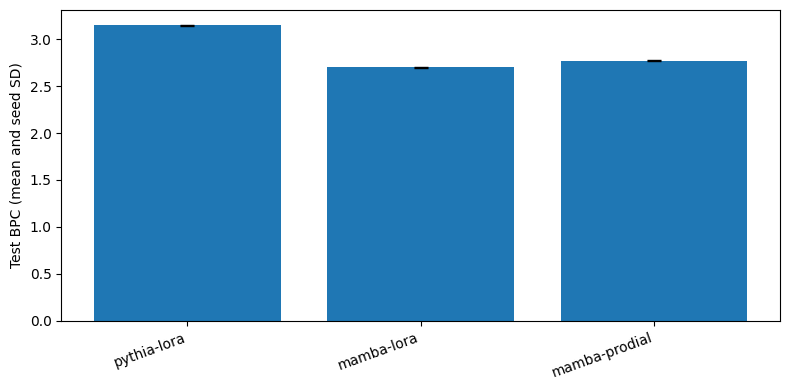

,id,seed,test_nll,test_ppl,test_bpc
0,pythia_lora_a52ad0d7a849,42,0.9178,2.504,3.1485
1,mamba_prodial_fc8b58a0f2f3,42,0.8070,2.241,2.7682
2,mamba_lora_dea7ad01262f,44,0.7888,2.201,2.7060
3,mamba_prodial_fc8b58a0f2f3,43,0.8096,2.247,2.7772
4,pythia_lora_a52ad0d7a849,43,0.9192,2.507,3.1532
5,mamba_prodial_fc8b58a0f2f3,44,0.8065,2.240,2.7665
6,mamba_lora_dea7ad01262f,43,0.7882,2.199,2.7037
7,mamba_lora_dea7ad01262f,42,0.7856,2.194,2.6949
8,pythia_lora_a52ad0d7a849,44,0.9144,2.495,3.1367


devtest scored once; test lock written before scoring. No further tuning on these documents.


In [12]:

def eval_overlap_report(test_docs, development_hashes, development_urls, dev_sig):
    worst = 0.
    hits = 0
    for d in test_docs:
        assert d['hash'] not in development_hashes and d['url'] not in development_urls, 'Exact test contamination'
        sig = shingles(d['text'])
        j = max([jaccard(sig, s) for s in dev_sig] or [0.])
        worst = max(worst, j)
        hits += (j >= .8)
    return dict(checked=len(test_docs), max_jaccard=worst, near_hits=hits)

def corpus_scores(recs):
    nats = sum(r['loss'] * r['tokens'] for r in recs)
    toks = sum(r['tokens'] for r in recs)
    chars = sum(r['chars'] for r in recs)
    correct = sum(r['accuracy'] * r['tokens'] for r in recs)
    assert toks > 0 and chars > 0
    return dict(nll=nats / toks, ppl=math.exp(nats / toks), accuracy=correct / toks,
                tokens=toks, chars=chars, bpc=nats / chars / math.log(2))

def score_docs(m, tok, rows):
    recs = []
    for d in rows:
        met = evaluate(m, chunks([d], tok), tok)
        recs.append(dict(document=d['hash'], source=d['url'], chars=len(d['text']), **met))
    return recs

EVAL_FINAL = []
if EVAL_ONLY:
    assert mood_state == MoodState.FULL and not RUN_FINAL_TEST, 'Eval-only keeps the cell-16 test path locked.'
    assert not RUN_SEARCH, 'Eval-only performs no training.'
    assert not (PROMOTE_ONLY or ONLY_SEARCH or FINAL_ONLY), 'Eval-only is a separate phase.'
    print('HF token source:', HF_TOKEN_SOURCE)
    assert HF_TOKEN, 'No HF token: attach the secret or approve the baked fallback.'
    cands = list(Path('/kaggle/input').rglob('manifest.json'))
    assert len(cands) == 1, f'Expected exactly one attached adapter dataset, found {len(cands)}'
    manifest = json.loads(cands[0].read_text(encoding='utf-8'))
    ddir = cands[0].parent
    assert len(manifest['checkpoints']) == 9, 'Expected the 9 v5 checkpoints'
    for e in manifest['checkpoints']:
        h = hashlib.sha256((ddir / e['file']).read_bytes()).hexdigest()
        assert h == e['sha256'], f"Hash mismatch, refusing to evaluate {e['file']}"
    print('adapter hash verify: 9/9 match manifest')
    assert len(FINAL_SPECS) == len(ARMS), 'EVAL_ONLY requires embedded lock specs'
    by_id = {}
    for e in manifest['checkpoints']:
        by_id.setdefault(e['id'], []).append(e['seed'])
    assert set(by_id) == {s['id'] for s in FINAL_SPECS} and all(sorted(v) == SEEDS for v in by_id.values()), 'Manifest must cover the embedded lock across all seeds'
    assert TRAIN_STATS and all((e['id'] + '/' + str(e['seed'])) in TRAIN_STATS for e in manifest['checkpoints']), 'Training stats missing'
    for e in manifest['checkpoints']:
        m = load_model(e['family']); t = TOKENIZERS[e['family']]
        attach_spec(m, e['spec'])
        load_adapter_state(m, torch.load(ddir / e['file'], map_location='cpu', weights_only=True))
        met = evaluate(m, TOKEN_DATA[e['family']]['validation'], t)
        delta = abs(met['loss'] - e['v5_best_val_loss'])
        assert delta < 1e-4, f"validation repro failed for {e['id']} seed {e['seed']}: delta {delta}"
        del m; gc.collect(); torch.cuda.empty_cache()
    print('validation repro: 9/9 within 1e-4 of v5 NLL')
    prodial_id = next(s['id'] for s in FINAL_SPECS if s['method'] == 'prodial')
    pe = next(e for e in manifest['checkpoints'] if e['id'] == prodial_id and e['seed'] == 42)
    m = load_model(pe['family']); t = TOKENIZERS[pe['family']]
    attach_spec(m, pe['spec'])
    load_adapter_state(m, torch.load(ddir / pe['file'], map_location='cpu', weights_only=True))
    before = evaluate(m, TOKEN_DATA[pe['family']]['validation'], t)['loss']
    inputs, _ = batch_tensors(TOKEN_DATA[pe['family']]['validation'][:1], t)
    with torch.no_grad():
        lb = m(**inputs, use_cache=False).logits
    merge(m); m.eval()
    with torch.no_grad():
        la = m(**inputs, use_cache=False).logits
    maxd = (lb - la).abs().max().item()
    after = evaluate(m, TOKEN_DATA[pe['family']]['validation'], t)['loss']
    write_json(OUT / 'fp32_merge_diagnostic.json',
               dict(id=pe['id'], seed=42,
                    note='evaluate() already runs fp32 (autocast disabled); this compares parametrized vs merged fp32 construction on validation only',
                    parametrized_val_nll=before, merged_fp32_val_nll=after,
                    nll_delta=after - before, max_abs_logit_delta_single_batch=maxd))
    print('fp32 merge diagnostic done: nll_delta=%.2e max_logit_delta=%.2e' % (after - before, maxd))
    del m, lb, la; gc.collect(); torch.cuda.empty_cache()
    test_revision = api.dataset_info(INDEPENDENT_TEST_DATASET, revision=TEST_REVISION_REQUESTED, token=HF_TOKEN).sha
    dev_docs = None
    try:
        dev_docs = clean_documents(load_dataset(INDEPENDENT_TEST_DATASET, TEST_CONFIG, revision=test_revision, split='dev', token=HF_TOKEN), TEST_TEXT_COLUMN, TEST_URL_COLUMN)
        print('rehearsal split dev:', len(dev_docs), 'documents')
    except Exception as e:
        print('no dev split to rehearse on:', str(e)[:200])
    if dev_docs is not None:
        (OUT / 'rehearsal').mkdir(exist_ok=True)
        for e in manifest['checkpoints']:
            m = load_model(e['family']); t = TOKENIZERS[e['family']]
            attach_spec(m, e['spec'])
            load_adapter_state(m, torch.load(ddir / e['file'], map_location='cpu', weights_only=True))
            recs = score_docs(m, t, dev_docs)
            write_json(OUT / 'rehearsal' / (e['id'] + f"_seed{e['seed']}_dev.json"),
                       dict(id=e['id'], seed=e['seed'], scores=corpus_scores(recs), per_document=recs))
            del m; gc.collect(); torch.cuda.empty_cache()
        print('dev rehearsal complete (rehearsal/ outputs are practice, not final scores)')
    TEST_DOCS = clean_documents(load_dataset(INDEPENDENT_TEST_DATASET, TEST_CONFIG, revision=test_revision, split=TEST_SPLIT, token=HF_TOKEN), TEST_TEXT_COLUMN, TEST_URL_COLUMN)
    assert len(TEST_DOCS) >= 20, 'Too few test documents.'
    assert len(TEST_DOCS) * len(docs) <= 25_000_000, 'Use scalable independent-test contamination audit.'
    development_hashes = {d['hash'] for d in docs}
    development_urls = {d['url'] for d in docs if not d['url'].startswith('row:')}
    dev_sig = [shingles(d['text']) for d in docs]
    overlap = eval_overlap_report(TEST_DOCS, development_hashes, development_urls, dev_sig)
    assert overlap['near_hits'] == 0, 'Near-duplicate test contamination'
    print('overlap gate:', overlap)
    analysis_plan = dict(
        metrics=['token-weighted NLL (primary)', 'PPL', 'next-token accuracy', 'BPC'],
        bpc_definition='total_nats/total_chars/ln(2) over scored targets; chars=len(document text)',
        chunking='MAX_LEN 256 with 1-token overlap; every target scored exactly once',
        first_token_caveat='each document first token is context-only and unscored; negligible but disclosed',
        comparison='mean and SD over 3 training seeds per method; paired whole-article bootstrap, seeds fixed',
        quality='repetition and distinct-n are diagnostics only; blinded speaker ratings required before fluency claims',
        rules=['no tuning on test, ever', 'devtest scored exactly once', 'overlap gate must pass before scoring'])
    accessed = OUT / 'test_access_manifest.json'
    assert not accessed.exists(), 'devtest already scored in this OUT: refusing a second scoring run'
    write_json(accessed, dict(dataset=INDEPENDENT_TEST_DATASET, config=TEST_CONFIG, revision=test_revision,
                              documents=[dict(hash=d['hash'], url=d['url']) for d in TEST_DOCS],
                              overlap=overlap, analysis_plan=analysis_plan, protocol=PROTOCOL_ID))
    TEST_BLOCKS = {f: chunks(TEST_DOCS, t) for f, t in TOKENIZERS.items()}
    assert TEST_BLOCKS['pythia'] == TEST_BLOCKS['mamba'], 'Test tokenization differs; token PPL no longer comparable.'
    import statistics
    for e in manifest['checkpoints']:
        m = load_model(e['family']); t = TOKENIZERS[e['family']]
        attach_spec(m, e['spec'])
        load_adapter_state(m, torch.load(ddir / e['file'], map_location='cpu', weights_only=True))
        recs = score_docs(m, t, TEST_DOCS)
        ts = TRAIN_STATS[e['id'] + '/' + str(e['seed'])]
        FINAL.append(dict(id=e['id'], family=e['family'], method=e['method'], seed=e['seed'], spec=e['spec'],
                          test=corpus_scores(recs), per_document=recs,
                          trainable_params=ts['trainable_params'],
                          train_tokens_per_second=ts['train_tokens_per_second'],
                          peak_train_gib=ts['peak_train_gib']))
        write_json(OUT / 'final_results.json', FINAL)
        del m; gc.collect(); torch.cuda.empty_cache()
    bpc_rows = []
    for fam, meth in ARMS:
        vals = [r['test']['bpc'] for r in FINAL if r['family'] == fam and r['method'] == meth]
        nlls = [r['test']['nll'] for r in FINAL if r['family'] == fam and r['method'] == meth]
        bpc_rows.append(dict(method=f'{fam}-{meth}',
                             nll_mean=sum(nlls) / len(nlls),
                             nll_sd=statistics.pstdev(nlls) if len(nlls) > 1 else 0.,
                             bpc_mean=sum(vals) / len(vals),
                             bpc_sd=statistics.pstdev(vals) if len(vals) > 1 else 0.,
                             seeds=len(vals)))
    pd.DataFrame(bpc_rows).to_csv(OUT / 'bpc_comparison.csv', index=False)
    plt.figure(figsize=(8, 4))
    plt.bar([r['method'] for r in bpc_rows], [r['bpc_mean'] for r in bpc_rows],
            yerr=[r['bpc_sd'] for r in bpc_rows], capsize=5)
    plt.xticks(rotation=20, ha='right'); plt.ylabel('Test BPC (mean and seed SD)')
    save_figure('test_bpc')
    display(pd.DataFrame([dict(id=r['id'], seed=r['seed'], test_nll=round(r['test']['nll'], 4),
                                test_ppl=round(r['test']['ppl'], 3), test_bpc=round(r['test']['bpc'], 4))
                          for r in FINAL]))
    print('devtest scored once; test lock written before scoring. No further tuning on these documents.')
